# Fuel station data: exploration and decisions

This notebook records how the fuel station data was explored, and why
`python manage.py ingest_fuel_stations` cleans, merges and locates stations the way it does.
The rules themselves live in `stations/ingest.py`; this notebook imports them instead of
re-implementing them, so its numbers match what the command does.

It is meant to be read, with its outputs saved. To regenerate them from a clean run:

```bash
pip install -r requirements-dev.txt
jupyter execute --inplace notebooks/station_data.ipynb
```

Everything below that uses the data files in the repo is computed live. Results that
needed other data or network access (other city datasets, the openrouteservice geocoder,
the OpenStreetMap download) are not re-run. They are marked **Recorded** and give the
numbers measured on 2026-11-02.

## Summary of decisions

| Decision | Main reason | Section |
|---|---|---|
| Trim every field and collapse repeated whitespace | Over 1,400 values have stray or double spaces | 2.2 |
| Keep only the 48 contiguous states and DC | 620 rows are Canadian; the route API only covers the contiguous US | 2.3 |
| Drop duplicate rows, ignoring the station name | Names of the same station vary only in spelling | 2.4, 7 |
| One station per OPIS ID, priced at the average of its rows | Repeated IDs differ in price, with no date or product to choose by | 2.5, 7 |
| Don't geocode with a web service | Quotas, highway-exit addresses geocode badly, ingestion would need the network | 4.1 |
| Locate by city with the GeoNames ZIP code file, after name normalization | Matches every city; other city datasets leave hundreds unmatched | 4.2, 4.3 |
| Locate at the OSM interstate exit when the address names one | City points are kilometres off the highway the station is on | 5 |
| Average an exit's points within 3 km of the one nearest the city | One exit has a point per ramp; the same number can exist elsewhere | 6.1, 6.2 |
| Ignore an exit more than 40 km from the city | Beyond that, the exit or city in the source is almost always wrong | 6.3 |

## 1. Setup

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'manage.py').exists())
sys.path.insert(0, str(ROOT))

from routing import LatLon, haversine_m
from stations.ingest import (
    CONTIGUOUS_US_STATES,
    EXIT_CLUSTER_RADIUS_M,
    EXIT_MAX_DISTANCE_M,
    FUEL_COLUMNS,
    build_stations,
    clean_field,
    load_city_points,
    load_exits,
    locate_exit,
    normalize_place,
    parse_exit_address,
)

FUEL_CSV = ROOT / 'fuel-prices-for-be-assessment.csv'
POSTAL_CODES = ROOT / 'geonames-us-postal-codes.txt'
EXITS_CSV = ROOT / 'osm-interstate-exits.csv'

pd.set_option('display.max_colwidth', 50)
plt.rcParams['figure.dpi'] = 90


def km(a, b):
    """Return the great-circle distance between two points, in km."""
    return haversine_m(a, b) / 1000

## 2. The fuel price file

### 2.1 First look

In [2]:
raw = pd.read_csv(FUEL_CSV, dtype=str, keep_default_na=False)
print(f'{len(raw)} rows, {raw.shape[1]} columns')
raw.head()

8151 rows, 7 columns


,OPIS Truckstop ID,Truckstop Name,Address,City,State,Rack ID,Retail Price
0,7,WOODSHED OF BIG CABIN,"I-44, EXIT 283 & US-69",Big Cabin,OK,307,3.00733333
1,9,KWIK TRIP #796,"I-94, EXIT 143 & US-12 & SR-21",Tomah,WI,420,3.28733333
2,20,PILOT TRAVEL CENTER #1243,"I-8, EXIT 119 & SR-85",Gila Bend,AZ,930,3.899
3,20,PILOT #1243,"I-8, EXIT 119 & SR-85",Gila Bend,AZ,930,3.899
4,28,LITTLEFIELD EXPRESS #2,"I-540, EXIT 12 & US-71",Fort Smith,AR,645,3.399


In [3]:
pd.DataFrame({
    'longest value': raw.apply(lambda col: col.str.len().max()),
    'distinct values': raw.nunique(),
})

,longest value,distinct values
OPIS Truckstop ID,5,6738
Truckstop Name,45,6550
Address,53,5624
City,40,3626
State,2,57
Rack ID,3,306
Retail Price,10,1020


What the file has, and what it lacks:

- **No coordinates, ZIP codes or street numbers.** Stations have to be located from the
  address, city and state.
- **No date and no product.** Nothing says when a price was observed or for which fuel.
- **The address is usually a highway and exit**, e.g. `I-44, EXIT 283 & US-69`, not a
  street address (section 3).
- **Rack ID** most likely identifies the wholesale fuel terminal (the "rack") whose price
  the station's retail price is based on. The file does not document it. It has 300 or
  so values shared by many stations, often across state lines, and it never differs
  between rows of the same station. It is stored but not used.

In [4]:
racks = raw.groupby('Rack ID')['State'].nunique()
print(f'{len(racks)} rack IDs; {(racks > 1).sum()} of them have stations in more than one state')

306 rack IDs; 146 of them have stations in more than one state


### 2.2 Whitespace

Many values have leading, trailing or repeated spaces, so the same name can be written
several ways. Every field is cleaned with `clean_field()`: trimmed, with each run of
whitespace collapsed to one space.

In [5]:
changed = raw.apply(lambda col: (col != col.map(clean_field)).sum())
changed.rename('values changed by cleaning').to_frame()

,values changed by cleaning
OPIS Truckstop ID,0
Truckstop Name,32
Address,189
City,1256
State,0
Rack ID,0
Retail Price,0


In [6]:
examples = raw.loc[raw['Truckstop Name'] != raw['Truckstop Name'].map(clean_field), 'Truckstop Name']
examples.head(5).map(repr).to_frame('raw name')

,raw name
578,'Uncle Petes Truck Stop'
634,'HIGHWAY 20 AUTO TRUCK PLAZA'
834,'SHOP A LOTT #3'
1400,'JIMS BEST STOP'
1436,'J AND H OIL'


In [7]:
fuel = raw.map(clean_field).rename(columns={column: field for field, column in FUEL_COLUMNS.items()})
fuel['opis_id'] = fuel['opis_id'].astype(int)
fuel['price'] = pd.to_numeric(fuel['price'])
fuel['price'].describe().round(3).to_frame()

,price
count,8151.000
mean,3.499
std,0.418
min,2.687
25%,3.216
50%,3.432
75%,3.699
max,6.399


All IDs and prices parse, and prices are in a plausible range, so the current file has
no invalid rows. The command still validates every row and skips and logs any that fail.

### 2.3 Rows outside the contiguous US

The file includes Canadian provinces. The route API only accepts points in the contiguous
US, so the command keeps an allowlist of the 48 contiguous states and DC instead of a
list of provinces to drop. That also excludes Alaska and Hawaii, of which this file has
none.

In [8]:
outside = fuel[~fuel['state'].isin(CONTIGUOUS_US_STATES)]
print(f'{len(outside)} rows outside the contiguous US')
outside['state'].value_counts().to_frame().T

620 rows outside the contiguous US


state,ON,AB,BC,MB,SK,YT,QC,NS,NB
count,217,180,121,42,36,8,6,6,4


In [9]:
us = fuel[fuel['state'].isin(CONTIGUOUS_US_STATES)].copy()
print(f'{len(us)} rows left in {us["state"].nunique()} states')

7531 rows left in 48 states


### 2.4 Duplicate rows

Some rows repeat exactly. More repeat except for the station name, whose spellings vary
(`PILOT #1243` vs `PILOT TRAVEL CENTER #1243`). Duplicates are dropped ignoring the name,
and the first spelling is kept. Section 7 shows why the name must be ignored here.

In [10]:
NOT_NAME = ['opis_id', 'address', 'city', 'state', 'rack_id', 'price']
print('exact duplicates:              ', us.duplicated().sum())
print('duplicates ignoring the name:  ', us.duplicated(subset=NOT_NAME).sum())
deduped = us.drop_duplicates(subset=NOT_NAME)

exact duplicates:               26
duplicates ignoring the name:   128


### 2.5 Repeated station IDs

Even without duplicates, some OPIS IDs have several rows. They are the same station:
the address, city, state and rack never differ between them. Only the price and the
name do.

In [11]:
groups = deduped.groupby('opis_id')
repeated = groups.filter(lambda g: len(g) > 1)
print(f'{deduped["opis_id"].nunique()} stations; {repeated["opis_id"].nunique()} have more than one row')
groups.size().value_counts().sort_index().rename_axis('rows per station').to_frame('stations').T

6626 stations; 487 have more than one row


rows per station,1,2,3,4,5,6
stations,6139,307,98,57,22,3


In [12]:
differs = repeated.groupby('opis_id').agg(lambda col: col.nunique() > 1)
differs.sum().rename('stations where the field differs').to_frame().T

,name,address,city,state,rack_id,price
stations where the field differs,143,0,0,0,0,487


In [13]:
spread = repeated.groupby('opis_id')['price'].agg(lambda p: p.max() - p.min())
spread.describe(percentiles=[0.5, 0.9]).round(3).rename('price spread, $/gal').to_frame().T

,count,mean,std,min,50%,90%,max
"price spread, $/gal",487.0,0.116,0.102,0.002,0.1,0.24,0.9


In [14]:
positions = repeated.groupby('opis_id').apply(lambda g: g.index.max() - g.index.min(), include_groups=False)
print(f'Median distance in the file between rows of one station: {positions.median():.0f} row(s)')
widest = spread.sort_values(ascending=False).index[:2]
repeated[repeated['opis_id'].isin(widest)].sort_values('opis_id')

Median distance in the file between rows of one station: 1 row(s)

,opis_id,name,address,city,state,rack_id,price
2799,65092,BP,"I-94 & US-12, EXIT 210",Dearborn,MI,325,3.579
2800,65092,BP,"I-94 & US-12, EXIT 210",Dearborn,MI,325,3.759
2801,65092,BP,"I-94 & US-12, EXIT 210",Dearborn,MI,325,4.099
2802,65092,BP,"I-94 & US-12, EXIT 210",Dearborn,MI,325,3.199
5497,69861,HUCKS FOOD & FUEL #379,"I-57, EXIT 53",Marion,IL,340,3.549
5498,69861,HUCKS FOOD & FUEL #379,"I-57, EXIT 53",Marion,IL,340,2.929
5499,69861,HUCKS FOOD & FUEL #379,"I-57, EXIT 53",Marion,IL,340,2.999


Rows of a station sit next to each other, and their prices differ by a median of
$0.10/gal and at most $0.90. Nothing in the file says which price is current or whether
they are different products. Section 7 covers how one price is chosen.

## 3. Address patterns

The address decides how precisely a station can be located. Just over half name an
interstate and an exit number, which `parse_exit_address()` extracts.

In [15]:
def address_kind(address):
    """Classify an address by what it says about the location."""
    if parse_exit_address(address):
        return 'interstate + exit'
    if re.search(r'\bEXIT\b', address, re.I):
        return 'other highway + exit'
    if re.match(r'^\d+\s+\S', address):
        return 'street address'
    if re.search(r'\b(I|US|SR|HWY|FM|CR)[- ]?\d', address, re.I):
        return 'highway, no exit'
    return 'other'


stations = deduped.drop_duplicates('opis_id').copy()  # first row per station, as the command uses
stations['kind'] = stations['address'].map(address_kind)
stations['kind'].value_counts().to_frame('stations')

,stations
kind,
interstate + exit,3537
"highway, no exit",2832
other highway + exit,199
other,53
street address,5


In [16]:
stations.groupby('kind')['address'].apply(lambda a: a.sample(min(4, len(a)), random_state=1).tolist()).to_frame('examples')

,examples
kind,
"highway, no exit","[US-81, US-41, I-75 & 696, SR-202]"
interstate + exit,"[I-80 EXIT 242 & SR 339, I-40, EXIT 37 & US-21..."
other,"[M-57, ST 14 BYPASS, US- 60 & HWY AD, HIGHWAY ..."
other highway + exit,"[HWY 29, EXIT 108, US-30, EXIT 313, US-131, EX..."
street address,"[214 PLAINS HIGHWAY, 206 R-11, 504 N CREGO RD,..."


An address often names two highways. The second is usually the road the exit connects
to (`I-44, EXIT 283 & US-69`), but two interstates appear where they share a road
(I-80 and I-90 across Ohio and Indiana) or meet. The rule is to use the interstate
written closest before the word EXIT, since that is the highway the number belongs to.

In [17]:
pd.DataFrame(
    [(a, parse_exit_address(a)) for a in [
        'I-44, EXIT 283 & US-69',
        'I-94 & US-12, EXIT 210',
        'I-80 & I-90, EXIT 3',
        'I-35W, EXIT 36 & CR-23',
        'I-81S, EXIT 10',
        'US-51 & US-2',
    ]],
    columns=['address', '(interstates to try, exit)'],
)

,address,"(interstates to try, exit)"
0,"I-44, EXIT 283 & US-69","([44], 283)"
1,"I-94 & US-12, EXIT 210","([94], 210)"
2,"I-80 & I-90, EXIT 3","([90], 3)"
3,"I-35W, EXIT 36 & CR-23","([35W, 35], 36)"
4,"I-81S, EXIT 10","([81S, 81], 10)"
5,US-51 & US-2,None


An interstate may carry a letter. Some letters are branches with their own exit
numbers (I-35E and I-35W around Dallas and Minneapolis, I-69C/E/W in south Texas), which
OSM maps as separate routes. Others are only a direction (I-81S, I-90E), which OSM does
not. So the lettered name is looked up first and the plain number second.

In [18]:
exit_points = pd.read_csv(EXITS_CSV, dtype={'interstate': str, 'exit_ref': str})
osm_names = set(exit_points['interstate'])
letters = stations['address'].str.extractall(r'\bI-? ?(\d+[A-Z])\b')[0].value_counts()
letters.to_frame('stations').assign(**{'separate route in OSM': [n in osm_names for n in letters.index]})

,stations,separate route in OSM
0,,
35W,9,True
35E,8,True
69C,4,True
69E,2,True
81N,1,False
81S,1,False
8I,1,False
76E,1,False
88E,1,False


## 4. Locating stations by city

### 4.1 Geocoding with a web service: not used

The project already uses openrouteservice (ORS) for routing, and ORS also geocodes, so
the first idea was to geocode each station or city. It was dropped:

- **Volume.** One request per address. Per city/state pair (below) that is about four
  days of the free quota; per station it is almost a week.
- **Addresses.** `I-44, EXIT 283 & US-69` is not something geocoders resolve reliably.
- **Ingestion would need the network and an API key,** and would have to resume across
  days when the quota runs out.

> **Recorded** (2026-11-02): a geocoding request with the project's ORS key returned
> `x-ratelimit-limit: 100`, resetting each minute. ORS staff on its forum give about
> 1,000 geocoding requests a day for a free key, with no batch endpoint. That daily
> figure was not verified.

In [19]:
pairs = stations[['city', 'state']].drop_duplicates()
print(f'{len(pairs)} distinct city/state pairs; {len(stations)} stations')
print(f'At about 1,000 requests a day: {len(pairs) / 1000:.1f} days for the pairs, {len(stations) / 1000:.1f} for every station')

3813 distinct city/state pairs; 6626 stations
At about 1,000 requests a day: 3.8 days for the pairs, 6.6 for every station


### 4.2 City datasets considered

Joining on city and state with a table of US places needs no network. Three tables were
tried; only the one used is in this repo.

> **Recorded** (2026-11-02), measured on the 7,505 rows left after exact-duplicate removal
> (3,808 city/state pairs):
>
> | City source | Unmatched pairs | Unmatched rows |
> |---|---|---|
> | SimpleMaps US cities (free version) | 372 | 596 |
> | SimpleMaps, with name normalization | 317 | 482 |
> | Census Gazetteer places | 298 | 503 |
> | Census Gazetteer places, with name normalization | 240 | 386 |
> | Census places + county subdivisions, with name normalization | 143 | 233 |
> | SimpleMaps + both Census files, with name normalization | 137 | 210 |
> | **GeoNames US postal codes, with name normalization** | **0** | **0** |

Why the others fall short:

- **[SimpleMaps](https://simplemaps.com/data/us-cities)** is built from Census places, so
  it shares their gaps. It also spells "Saint" as "St." and joins names such as "McCalla".
- **[Census Gazetteer places](https://www.census.gov/geographies/reference-files/time-series/geo/gazetteer-files.html)**
  use legal names: Pecos, TX is "Town of Pecos city" and Utica, IL is "North Utica
  village". Townships (Mahwah, NJ) are in a separate county-subdivisions file.
- **Neither has unincorporated places** such as Ruther Glen, VA, Breezewood, PA or Jean, NV,
  where many truck stops are.

The fuel file's cities are mailing-address cities: the place name the US Postal Service
uses for a ZIP code. GeoNames lists exactly that for every ZIP code, which is why it
matches everything.

### 4.3 GeoNames ZIP codes

In [20]:
GEONAMES_COLUMNS = ['country', 'zip', 'place', 'state_name', 'state', 'county', 'county_code',
                    'community', 'community_code', 'lat', 'lon', 'accuracy']
geonames = pd.read_csv(POSTAL_CODES, sep='\t', header=None, names=GEONAMES_COLUMNS,
                       dtype={'zip': str}, keep_default_na=False, quoting=3)
print(f'{len(geonames)} ZIP codes')
geonames[['zip', 'place', 'state', 'lat', 'lon']].head()

41490 ZIP codes


,zip,place,state,lat,lon
0,99553,Akutan,AK,54.1430,-165.7854
1,99571,Cold Bay,AK,55.1858,-162.7211
2,99583,False Pass,AK,54.8542,-163.4113
3,99612,King Cove,AK,55.0628,-162.3056
4,99661,Sand Point,AK,55.3192,-160.4914


In [21]:
plain = set(zip(geonames['place'].str.lower(), geonames['state']))
normalized = set(zip(geonames['place'].map(normalize_place), geonames['state']))

pairs = pairs.assign(
    plain=[(c.lower(), s) in plain for c, s in zip(pairs['city'], pairs['state'])],
    normalized=[(normalize_place(c), s) in normalized for c, s in zip(pairs['city'], pairs['state'])],
)
print('unmatched pairs, lowercase only:', (~pairs['plain']).sum())
print('unmatched pairs, normalized:    ', (~pairs['normalized']).sum())
pairs[~pairs['plain']]

unmatched pairs, lowercase only: 3
unmatched pairs, normalized:     0


,city,state,plain,normalized
1082,De Forest,WI,False,True
2640,Mc Leansville,NC,False,True
2844,Winston Salem,NC,False,True


`normalize_place()` lowercases, drops periods and apostrophes, shortens Saint, Fort and
Mount, and removes spaces and hyphens. A city's point is the plain average of its ZIP
code points (`load_city_points()`).

### 4.4 How precise is a city point?

For a small town with one ZIP code, the city point is that ZIP's point. A large city has
dozens, and its point is their average, which can be tens of kilometres from where a
station actually is. Below, each station's city is bucketed by how far its farthest ZIP
point is from the city point.

In [22]:
geonames['key'] = list(zip(geonames['place'].map(normalize_place), geonames['state']))
city_points = load_city_points(POSTAL_CODES)


def zip_spread_km(group):
    """Return how far the city's farthest ZIP point is from the city point."""
    centre = city_points[group.name]
    return max(km(centre, LatLon(lat, lon)) for lat, lon in zip(group['lat'], group['lon']))


city_spread = geonames.groupby('key')[['lat', 'lon']].apply(zip_spread_km)
stations['key'] = list(zip(stations['city'].map(normalize_place), stations['state']))
stations['city_point'] = stations['key'].map(city_points)
stations['zip_spread_km'] = stations['key'].map(city_spread)

BUCKETS = [-1, 0, 5, 15, 30, 1000]
LABELS = ['1 ZIP', '<5 km', '5-15 km', '15-30 km', '30+ km']
stations['spread'] = pd.cut(stations['zip_spread_km'], BUCKETS, labels=LABELS)
stations['spread'].value_counts().sort_index().to_frame('stations')

,stations
spread,
1 ZIP,4283
<5 km,749
5-15 km,1032
15-30 km,444
30+ km,118


In [23]:
by_city = stations.groupby(['city', 'state']).agg(stations=('opis_id', 'size'), zip_spread_km=('zip_spread_km', 'first'))
by_city.sort_values('zip_spread_km', ascending=False).head(6).round(0)

,,stations,zip_spread_km
city,state,,
Orlando,FL,4,65.0
Tucson,AZ,7,54.0
Jacksonville,FL,12,47.0
Prescott,AZ,1,45.0
Las Vegas,NV,5,40.0
El Paso,TX,12,37.0


Without exit matching, all stations of a city would share one point, however far apart
they really are. The cities with the most stations:

In [24]:
stations.groupby(['city', 'state']).size().sort_values(ascending=False).head(5).to_frame('stations')

,,stations
city,state,
Phoenix,AZ,22
San Antonio,TX,19
Midland,TX,17
Amarillo,TX,17
Indianapolis,IN,15


## 5. Locating stations at interstate exits

Over half the stations are at an interstate exit (section 3), and OpenStreetMap (OSM) maps
interstate exits as `highway=motorway_junction` points tagged with the exit number. So
"state + interstate + exit" can be turned into the exit's coordinates.

### 5.1 The exits file

> **Recorded** (2026-11-02): `osm-interstate-exits.csv` was built from the
> [Overpass API](https://overpass-api.de), one query per contiguous state:
>
> ```
> [out:json][timeout:300];
> area["ISO3166-2"="US-{state}"]->.a;
> way(area.a)[highway~"^motorway$"][ref~"(^|;) *I[ -]?[0-9]"];
> node(w)[highway=motorway_junction]->.j;
> foreach.j(out center; way(bn)[highway=motorway]; out tags;);
> ```
>
> Each exit point with a `ref` became one row per interstate named in the `ref` of the
> motorway it sits on (`I 35W;US 287` gives `35W`), keeping the branch letter. The raw
> responses were 37 MB; the CSV is 1.4 MB. The public Overpass server throttled the
> download partway, and the 48 states took about 30 minutes, which is why ingestion reads
> the saved file instead of querying OSM.

In [25]:
print(f'{len(exit_points)} rows, {exit_points["state"].nunique()} states')
exit_points.head()

32669 rows, 48 states


,state,interstate,exit_ref,lat,lon,osm_node_id
0,AL,10,10,30.533485,-88.247110,298153743
1,AL,10,10,30.541147,-88.231998,298154080
2,AL,10,13,30.562140,-88.199200,57876749
3,AL,10,13,30.557114,-88.205653,57909038
4,AL,10,15A,30.580815,-88.170977,57778374


### 5.2 Coverage

In [26]:
exits = load_exits(EXITS_CSV)


def find_exit(address, state):
    """Look up the exit in the address the way the command does.

    Returns (interstate, exit number, OSM points); the points are empty if OSM lacks the
    exit. Returns (None, None, None) if the address has no interstate exit.
    """
    parsed = parse_exit_address(address)
    if parsed is None:
        return None, None, None
    names, number = parsed
    for name in names:
        if exits.get((state, name, number)):
            return name, number, exits[(state, name, number)]
    return None, number, []


lookups = [find_exit(a, s) for a, s in zip(stations['address'], stations['state'])]
stations['interstate'] = [interstate for interstate, _, _ in lookups]
stations['exit_number'] = [number for _, number, _ in lookups]
stations['exit_points'] = [points for _, _, points in lookups]
has_exit = stations['exit_points'].notna()
found = stations['exit_points'].map(bool)
print(f'{has_exit.sum()} stations have an interstate exit in the address')
print(f'{found.sum()} of them ({found.sum() / has_exit.sum():.0%}) are found in OSM')

3537 stations have an interstate exit in the address
3211 of them (91%) are found in OSM


### 5.3 What exits add over city points

Exits do not locate any station that GeoNames cannot; they make about half the stations
more precise. Below, the distance between each station's exit and its city point,
by how spread out the city is.

In [27]:
matched = stations[found].copy()
matched['exit_point'] = [locate_exit(p, c) for p, c in zip(matched['exit_points'], matched['city_point'])]
matched['exit_to_city_km'] = [km(e, c) for e, c in zip(matched['exit_point'], matched['city_point'])]
near = matched[matched['exit_to_city_km'] <= EXIT_MAX_DISTANCE_M / 1000]

near.groupby('spread', observed=True)['exit_to_city_km'].agg(
    stations='size',
    median_km='median',
    moved_over_5_km=lambda d: (d > 5).sum(),
    moved_over_10_km=lambda d: (d > 10).sum(),
).round(1)

,stations,median_km,moved_over_5_km,moved_over_10_km
spread,,,,
1 ZIP,1963,3.6,630,150
<5 km,336,4.8,155,39
5-15 km,508,6.6,355,129
15-30 km,281,9.9,232,139
30+ km,57,11.0,54,32


The biggest moves are in sprawling cities, but small towns gain too: truck stops sit at
the exit, often several kilometres outside town.

What matters for the planner is whether a station appears near the route. The planner
is expected to keep stations within some distance of the route line. For stations at an
exit, the table below shows how far their city point is from the interstate they are
actually on. The distance is measured to the nearest exit point of that interstate, so
it slightly overstates the distance to the road itself.

In [28]:
interstate_points = {}
for (state, interstate, _), points in exits.items():
    interstate_points.setdefault((state, interstate), []).extend(points)

on_interstate = pd.Series([
    min(km(city, p) for p in interstate_points[(state, interstate)])
    for city, state, interstate in zip(near['city_point'], near['state'], near['interstate'])
])
pd.DataFrame({
    'corridor width': [f'{w} km' for w in (1, 2, 5, 10)],
    'stations outside it with city points': [(on_interstate > w).sum() for w in (1, 2, 5, 10)],
    'share': [f'{(on_interstate > w).mean():.0%}' for w in (1, 2, 5, 10)],
})

,corridor width,stations outside it with city points,share
0,1 km,2725,87%
1,2 km,2062,66%
2,5 km,658,21%
3,10 km,139,4%


With city points alone, a tight corridor misses most interstate stations, and a wide one
lets in stations on other roads or across town. Exit points sit on the highway itself.

## 6. Exit matching rules

### 6.1 One exit, several points

OSM places an exit point where each off-ramp leaves the highway. A divided highway has a
ramp per direction, on either side of the bridge, and split exits (283A, 283B) add more.
Addresses rarely give the letter, so all points of an exit number are considered.

In [29]:
def widest_gap_km(points):
    """Return the largest distance between two of the points."""
    return max((km(a, b) for a in points for b in points), default=0)


used = {
    (state, interstate, number): points
    for state, interstate, number, points
    in zip(matched['state'], matched['interstate'], matched['exit_number'], matched['exit_points'])
}
gaps = pd.Series({key: widest_gap_km(points) for key, points in used.items()})
gap_buckets = pd.cut(gaps, [-1, 0, 0.5, 1, 3, 10_000],
                     labels=['1 point', 'within 0.5 km', '0.5-1 km', '1-3 km', 'over 3 km'])
gap_buckets.value_counts().sort_index().rename_axis('distance between an exit\'s points').to_frame('exits')

,exits
distance between an exit's points,
1 point,61
within 0.5 km,150
0.5-1 km,1164
1-3 km,953
over 3 km,60


The station is usually on the crossroad, between the ramps, so the points of the
interchange are averaged. The average is close to any single point; the difference only
matters for a corridor under a kilometre or so.

In [30]:
def nearest(points, city):
    return min(points, key=lambda p: km(p, city))


shift = pd.Series([km(nearest(p, c), e) for p, c, e in zip(near['exit_points'], near['city_point'], near['exit_point'])])
print(f'Nearest single point vs the average: median {shift.median():.2f} km, max {shift.max():.2f} km')

Nearest single point vs the average: median 0.46 km, max 1.65 km


### 6.2 The same exit number in different places

A few exit numbers exist more than once on the same interstate in one state, hundreds of
kilometres apart. Mostly this is where two interstates share a road: the shared stretch
carries both route numbers but only one set of exit numbers. For example, I-64 runs on
I-81's road near Staunton, VA, so I-81's exit 205 is also listed under I-64, far from
I-64's own exit 205. Keeping branch letters (section 3) already separates I-35E from
I-35W, which would otherwise top this list.

In [31]:
gaps[gaps > 3].sort_values(ascending=False).head(8).round(0).rename_axis(['state', 'interstate', 'exit']).to_frame('widest gap, km')

,,,"widest gap, km"
state,interstate,exit,
AR,40,5.0,383.0
TX,30,1.0,339.0
NY,86,12.0,276.0
AR,49,24.0,248.0
MO,55,40.0,239.0
WI,39,171.0,225.0
VA,64,205.0,186.0
KY,65,121.0,176.0


So `locate_exit()` takes the point nearest the station's city and averages only the
points within 3 km of it, which is one interchange. The same number elsewhere is
ignored. Any radius from about 3 to 20 km gives the same result, since an interchange
fits within 3 km and the duplicates are 100+ km away.

### 6.3 When to distrust an exit

If the exit in the address is far from the listed city, one of the two is wrong:

- **The exit:** a typo, an exit renumbered since (New York moved I-81 to mileage-based
  numbers), or a same-numbered exit on another road.
- **The city:** rural stations often use the mailing address of a town 20-35 km away.

A wrong exit can be hundreds of kilometres off, while a loose city is off by the size of
its area. So beyond some distance the city point is used instead.

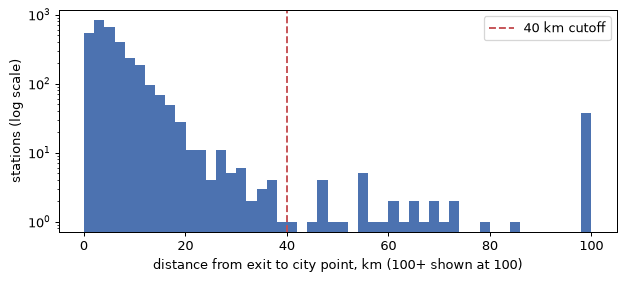

In [32]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(matched['exit_to_city_km'].clip(upper=100), bins=50, color='#4C72B0')
ax.axvline(EXIT_MAX_DISTANCE_M / 1000, color='#C44E52', linestyle='--', label='40 km cutoff')
ax.set_yscale('log')
ax.set_xlabel('distance from exit to city point, km (100+ shown at 100)')
ax.set_ylabel('stations (log scale)')
ax.legend()
plt.show()

In [33]:
DISTANCE_BANDS = [0, 5, 15, 25, 40, 60, 100_000]
DISTANCE_LABELS = ['<5 km', '5-15 km', '15-25 km', '25-40 km', '40-60 km', '60+ km']
matched['distance_band'] = pd.cut(matched['exit_to_city_km'], DISTANCE_BANDS, labels=DISTANCE_LABELS)
matched['distance_band'].value_counts().sort_index().to_frame('stations')

,stations
distance_band,
<5 km,1719
5-15 km,1267
15-25 km,125
25-40 km,34
40-60 km,15
60+ km,51


In [34]:
COLUMNS = ['name', 'address', 'city', 'state', 'exit_to_city_km']
for band in ['15-25 km', '25-40 km', '40-60 km', '60+ km']:
    print(band)
    print(matched.loc[matched['distance_band'] == band, COLUMNS].pipe(lambda df: df.sample(min(4, len(df)), random_state=3)).round(1).to_string(header=False), '\n')

15-25 km
1605  FLYING J TRAVEL PLAZA #703                    I-40, EXIT 140  Oklahoma City  OK  18.5
6470      LOVES TRAVEL STOP #793  I-840, EXIT 67 & COUCHVILLE PIKE   Mount Juliet  TN  15.7
282                FLYING J #305                     I-40, EXIT 39      Jamestown  NM  23.6
1186     SAPP BROS TRAVEL CENTER  I-80, EXIT 440 & SR-50, EXIT 440          Omaha  NE  15.2 

25-40 km
696               A C TRUCKSTOP        I-80, EXIT 290      Laramie  WY  27.8
6655  NAVAJO BLUE TRAVEL CENTER         I-40 EXIT 219    Flagstaff  AZ  34.1
3439                         BP  I-16, EXIT 90 & US-1    Twin City  GA  25.7
4827                 PILOT #467        I-37, EXIT 125  San Antonio  TX  28.7 

40-60 km
5232       GOOD 2 GO #418  I-15, EXIT 273 & US-54 & US-91          Mona  UT  55.1
2430        CM SPRINGHILL                   I-20, EXIT 44    Springhill  LA  47.0
541            SPEEDYS #6                   I-35, EXIT 33  Saint Joseph  MO  54.7
3253  One9 SPEEDWAY #6753                    I-

Up to 25 km the matches are real: big cities and rural mailing towns. Between 25 and
40 km they are still mostly real, such as the travel center at I-40 exit 219 east of
Flagstaff, or I-37 exit 125 on the south-east edge of San Antonio. Beyond 40 km they are
mostly wrong. Sometimes the source is wrong: `Saint Joseph, MO, I-35 EXIT 33` cannot be
right, since St. Joseph is on I-29. Sometimes the lookup is: Clifton Park, NY is at
exit 10 of the I-87 Northway, but the OSM file has no Northway exit 10, only the I-87
exit 10s near New York City, about 200 km away. Either way, the city point is the safer
choice.

A cutoff relative to the city's size looked better on paper but rejects real stations,
because a single-ZIP rural town can still cover a large area:

In [35]:
d, s = matched['exit_to_city_km'], matched['zip_spread_km']
rules = {
    'fixed 25 km': d > 25,
    'fixed 40 km': d > 40,
    'fixed 60 km': d > 60,
    'city ZIP spread + 15 km': d > s + 15,
    'city ZIP spread + 25 km': d > s + 25,
}
pd.Series({rule: rejected.sum() for rule, rejected in rules.items()}).to_frame('stations sent back to the city point')

,stations sent back to the city point
fixed 25 km,100
fixed 40 km,66
fixed 60 km,51
city ZIP spread + 15 km,133
city ZIP spread + 25 km,87


In [36]:
matched.loc[(d <= 40) & (d > s + 15), COLUMNS].head(5).round(1)

,name,address,city,state,exit_to_city_km
43,COFFEE CUP FUEL STOP #5,"I-90, EXIT 154 & US-16",Moorcroft,WY,18.5
282,FLYING J #305,"I-40, EXIT 39",Jamestown,NM,23.6
318,LOVES TRAVEL STOP #229,I-40 EXIT 96 & SR-207,Panhandle,TX,18.7
354,CIRCLE K #2723713,"I-81, EXIT 205",Staunton,VA,29.1
355,FAS MART #3555,"I-64, EXIT 136 & US-15",Gordonsville,VA,22.3


A fixed 40 km sits where matches turn from mostly real to mostly wrong, so it is the
cutoff used (`EXIT_MAX_DISTANCE_M`).

## 7. One price per station

Each station needs one price for the planner to compare. With no date or product to go
by, the options were:

| Rule | Problem |
|---|---|
| Lowest | Stations with more rows get more chances to look cheap |
| Highest | Consistently pessimistic |
| First or last row | Treats file order as meaningful, and nothing suggests it is |
| **Average** | **No bias; every station is treated the same whatever its number of rows** |

The bias of the lowest price is visible in the data: the more rows a station has, the
further its lowest price sits below its average.

In [37]:
per_station = deduped.groupby('opis_id')['price'].agg(['mean', 'min', 'size'])
(per_station['mean'] - per_station['min']).groupby(per_station['size']).mean().round(3) \
    .rename_axis('rows per station').to_frame('average minus lowest, $/gal').T

rows per station,1,2,3,4,5,6
"average minus lowest, $/gal",0.0,0.038,0.078,0.096,0.104,0.124


The duplicate check ignores the name because otherwise a price would count twice when
its row appears under two spellings. A station listed at \$3.00 as `PILOT #1243`,
\$3.00 as `PILOT TRAVEL CENTER #1243` and \$3.50 would average \$3.17 instead of \$3.25.
In this file:

In [38]:
exact = us.drop_duplicates().groupby('opis_id')['price'].mean()
ignoring_name = deduped.groupby('opis_id')['price'].mean()
changed = (exact - ignoring_name).abs() > 1e-9
print(f'{changed.sum()} stations get a different average when names are ignored')
print(f'largest difference: ${(exact - ignoring_name).abs().max():.3f}/gal')

12 stations get a different average when names are ignored
largest difference: $0.033/gal


## 8. Result

`build_stations()` is what the ingest command runs. Its report matches the command's
summary.

In [39]:
records, report = build_stations(FUEL_CSV, POSTAL_CODES, EXITS_CSV)
pd.Series(vars(report)).to_frame('count')

,count
rows_read,8151
rows_invalid,0
rows_outside_us,620
rows_duplicate,128
stations_without_city,0
stations_at_exit,3145
stations_at_city,3481
exits_too_far,66


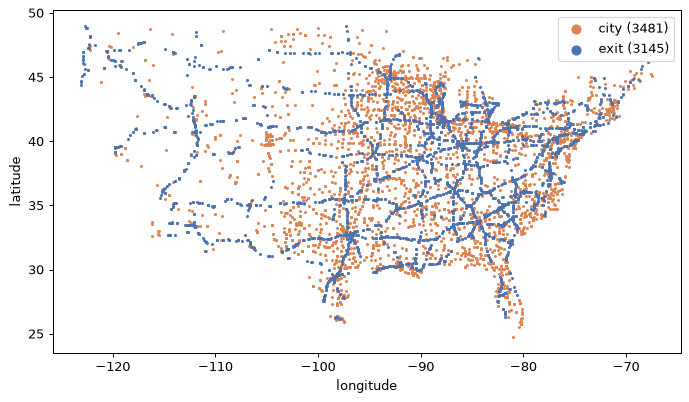

In [40]:
result = pd.DataFrame(records)
fig, ax = plt.subplots(figsize=(9, 5))
for precision, colour in [('city', '#DD8452'), ('exit', '#4C72B0')]:
    part = result[result['location_precision'] == precision]
    ax.scatter(part['lon'], part['lat'], s=2, color=colour, label=f'{precision} ({len(part)})')
ax.set_aspect(1.25)
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
ax.legend(markerscale=5)
plt.show()

## 9. Limitations and ideas

- **Half the stations are located at city level.** Their address has no interstate
  exit (`US-51 & US-2`, `SR 30`). Matching the highway in the address against OSM roads
  near the city could place many of them, at the cost of a much larger OSM download.
- **Exits on other highways** (`US-23, EXIT 5`) are not looked up. The OSM extract only
  has interstates.
- **Only the interstate nearest the word EXIT is tried.** Where two interstates meet and
  the number belongs to the first, the station falls back to its city.
- **The city point is an unweighted mean of ZIP points.** A median would be less pulled
  by outlying ZIPs; population weights would need another source.
- **Prices have no date.** If the source ever adds one, the latest price should replace
  the average.
- **Locations were not checked against true station positions.** The Big Cabin, OK
  station was spot-checked against its exit; OSM's mapped fuel stations
  (`amenity=fuel`) could be used to check more.